### 1. Setup Environment


In [1]:
import sys, json, joblib
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

ROOT_DIR = Path(r"c:\Project\napasloka\napasloka")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import pandas as pd

summary_path = ROOT_DIR / "artifacts" / "summary_metrics.csv"
df_summary = pd.read_csv(summary_path)
df_summary


,location,pollutant,scenario,algorithm,mae,rmse,mape,r2,training_time_seconds,prediction_time_seconds,best_params
0,taman-kamal,CO,scenario_1,xgboost,63.622424,95.122871,6.227183,0.981961,9.730577,0.006736,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
1,taman-kamal,CO,scenario_1,lightgbm,62.475965,92.168714,6.145671,0.983064,5.649717,0.022104,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
2,taman-kamal,CO,scenario_2,xgboost,69.062951,100.652386,7.033787,0.979803,13.110022,0.006275,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
3,taman-kamal,CO,scenario_2,lightgbm,65.859890,96.135442,6.742276,0.981575,7.262533,0.021443,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
4,taman-kamal,CO2,scenario_1,xgboost,1.187560,1.654335,0.255770,0.982027,1.528648,0.006892,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
...,...,...,...,...,...,...,...,...,...,...,...
115,cibinong,CO,scenario_2,lightgbm,58.531201,82.637753,5.273384,0.981507,8.227737,0.021661,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
116,cibinong,CO2,scenario_1,xgboost,2.205892,3.112544,0.455648,0.985864,1.852382,0.006727,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
117,cibinong,CO2,scenario_1,lightgbm,2.127231,2.991223,0.439458,0.986944,4.850213,0.020659,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
118,cibinong,CO2,scenario_2,xgboost,2.216560,3.189861,0.456774,0.985152,10.274093,0.005932,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."


### 2. Perbandingan Hasil Metrik Evaluasi

In [2]:
agg_summary = df_summary.groupby(["pollutant", "scenario"]).agg(
    r2=("r2", "mean"),
    mae=("mae", "mean"),
    rmse=("rmse", "mean"),
    mape=("mape", "mean"),
    training_time=("training_time_seconds", "mean")
).reset_index()

agg_summary["r2"] = agg_summary["r2"].round(4)
agg_summary["mae"] = agg_summary["mae"].round(2)
agg_summary["rmse"] = agg_summary["rmse"].round(2)
agg_summary["mape"] = agg_summary["mape"].round(2)
agg_summary["training_time"] = agg_summary["training_time"].round(2)
agg_summary.columns = ["Polutan", "Skenario", "R²", "MAE", "RMSE", "MAPE (%)", "Waktu Latih (s)"]

display(agg_summary)

,Polutan,Skenario,R²,MAE,RMSE,MAPE (%),Waktu Latih (s)
0,CO,scenario_1,0.9785,91.29,133.76,7.26,4.17
1,CO,scenario_2,0.9771,92.22,137.89,7.41,9.37
2,CO2,scenario_1,0.9810,1.59,2.28,0.34,3.26
3,CO2,scenario_2,0.9804,1.61,2.31,0.34,8.69


✓ Grafik Skenario disimpan di: gambar_komparasi_skenario.png


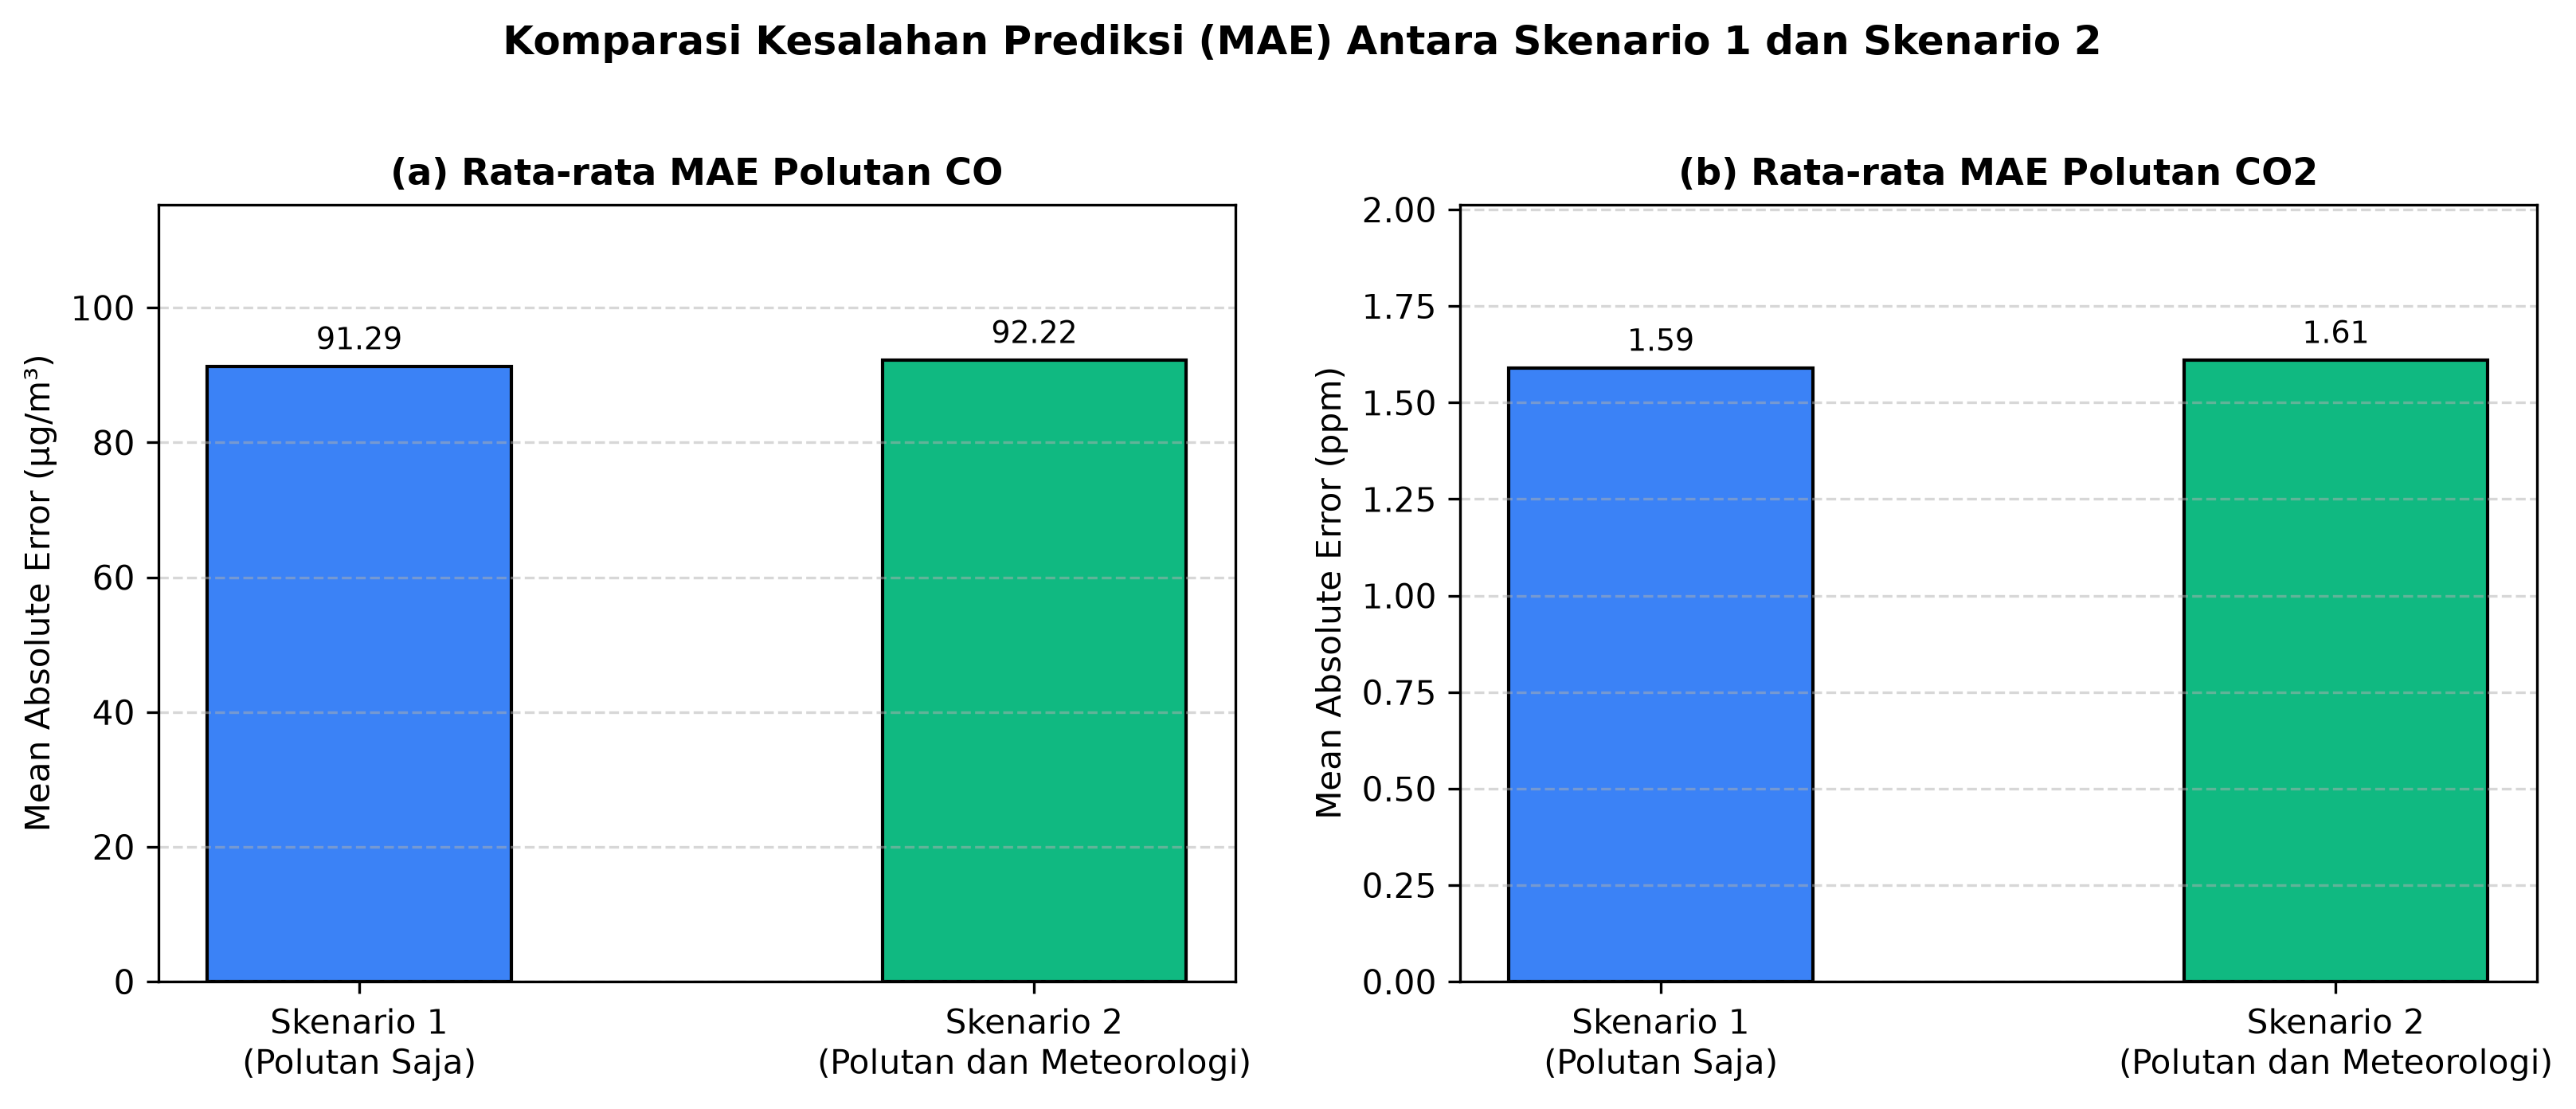

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=300)

# Panel CO
co_data = agg_summary[agg_summary["Polutan"] == "CO"]
bars1 = ax1.bar(["Skenario 1\n(Polutan Saja)", "Skenario 2\n(Polutan dan Meteorologi)"], co_data["MAE"], color=["#3b82f6", "#10b981"], edgecolor="black", width=0.45)
ax1.set_title("(a) Rata-rata MAE Polutan CO", fontsize=11, fontweight="bold")
ax1.set_ylabel("Mean Absolute Error (µg/m³)", fontsize=10)
ax1.grid(axis="y", linestyle="--", alpha=0.5)
ax1.bar_label(bars1, fmt="%.2f", padding=3, fontsize=9)
ax1.set_ylim(0, co_data["MAE"].max() * 1.25)

# Panel CO2
co2_data = agg_summary[agg_summary["Polutan"] == "CO2"]
bars2 = ax2.bar(["Skenario 1\n(Polutan Saja)", "Skenario 2\n(Polutan dan Meteorologi)"], co2_data["MAE"], color=["#3b82f6", "#10b981"], edgecolor="black", width=0.45)
ax2.set_title("(b) Rata-rata MAE Polutan CO2", fontsize=11, fontweight="bold")
ax2.set_ylabel("Mean Absolute Error (ppm)", fontsize=10)
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.bar_label(bars2, fmt="%.2f", padding=3, fontsize=9)
ax2.set_ylim(0, co2_data["MAE"].max() * 1.25)
plt.suptitle("Komparasi Kesalahan Prediksi (MAE) Antara Skenario 1 dan Skenario 2", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
out_scen_img = ROOT_DIR / "artifacts" / "gambar_komparasi_skenario.png"
plt.savefig(out_scen_img, dpi=300, bbox_inches="tight")
print(f"✓ Grafik Skenario disimpan di: {out_scen_img.name}")
plt.show()

✓ Gambar komparasi 4 metrik berhasil disimpan di: gambar_komparasi_skenario_lengkap.png


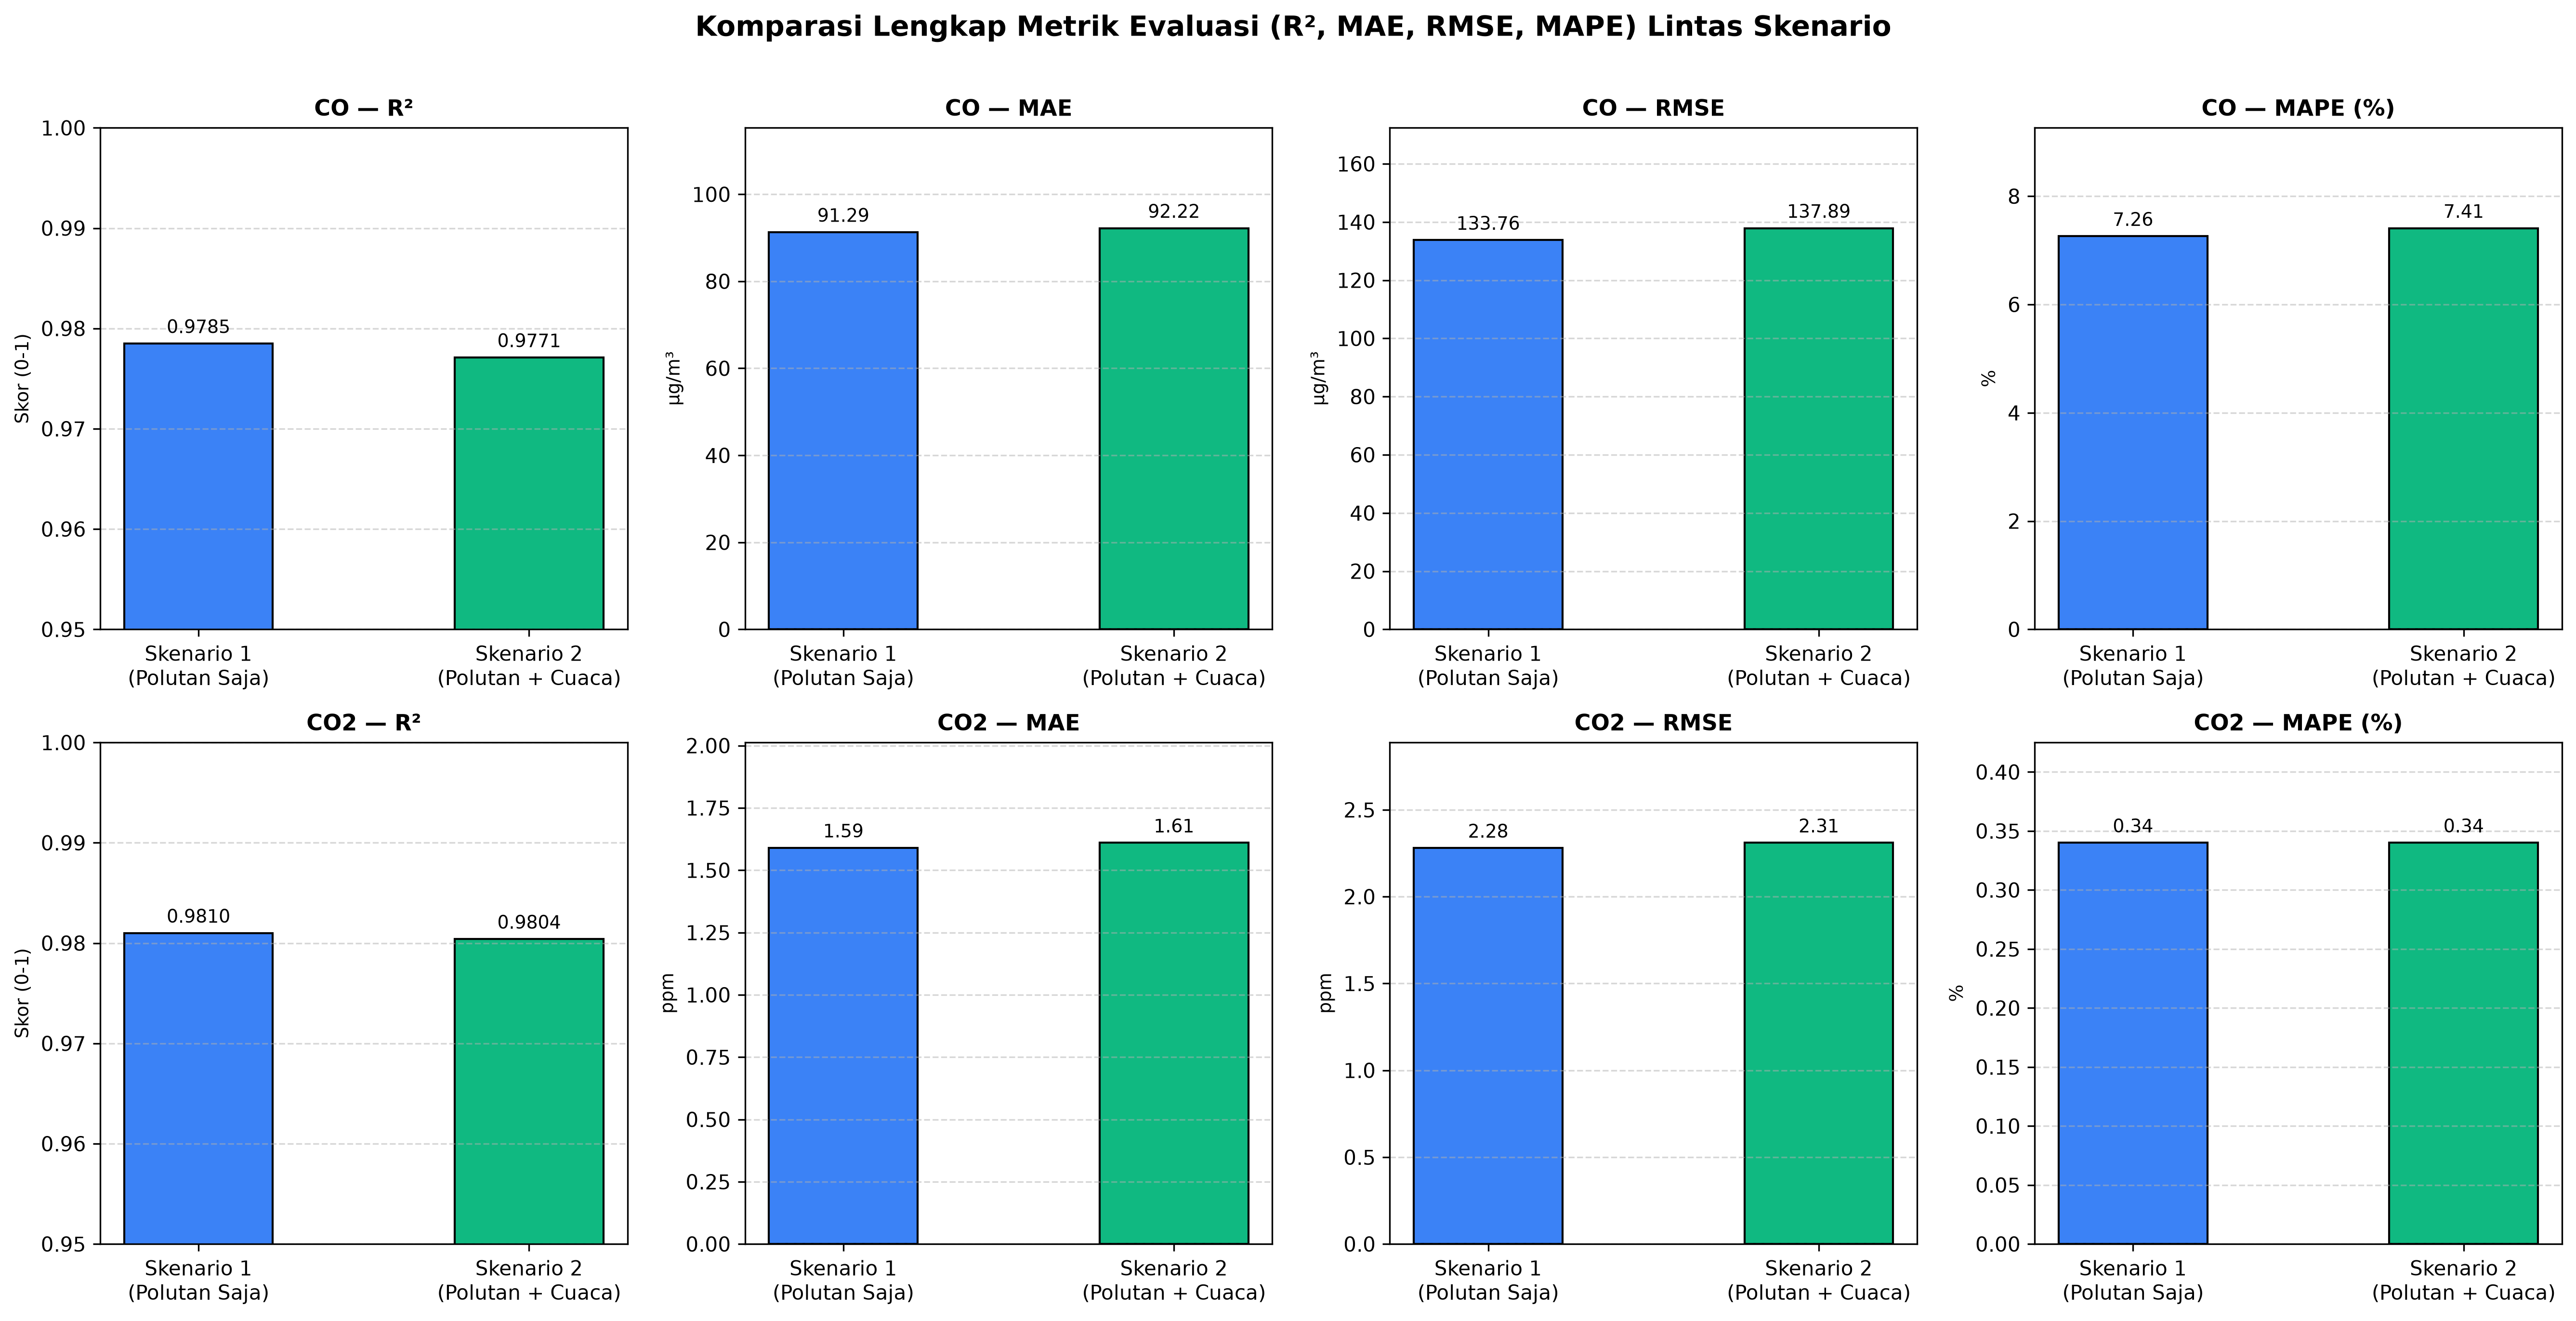

In [4]:
# Konfigurasi grid 2 baris (Baris 1: CO, Baris 2: CO2) dan 4 kolom (R2, MAE, RMSE, MAPE)
fig, axes = plt.subplots(2, 4, figsize=(18, 9), dpi=300)

metrics = ["R²", "MAE", "RMSE", "MAPE (%)"]
metric_units_co = ["Skor (0-1)", "µg/m³", "µg/m³", "%"]
metric_units_co2 = ["Skor (0-1)", "ppm", "ppm", "%"]

scenarios = ["Skenario 1\n(Polutan Saja)", "Skenario 2\n(Polutan + Cuaca)"]
colors = ["#3b82f6", "#10b981"]

co_data = agg_summary[agg_summary["Polutan"] == "CO"].sort_values("Skenario")
co2_data = agg_summary[agg_summary["Polutan"] == "CO2"].sort_values("Skenario")

# 1. Baris Pertama: Polutan CO
for i, metric in enumerate(metrics):
    ax = axes[0, i]
    vals = co_data[metric].values
    bars = ax.bar(scenarios, vals, color=colors, edgecolor="black", width=0.45)
    
    ax.set_title(f"CO — {metric}", fontsize=11, fontweight="bold")
    ax.set_ylabel(metric_units_co[i], fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    
    # Format label angka di atas batang
    fmt = "%.4f" if metric == "R²" else "%.2f"
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9)
    
    # Batas sumbu Y agar label tidak terpotong
    if metric == "R²":
        ax.set_ylim(0.95, 1.0)  # Zoom in agar selisih R2 yang tipis tetap terlihat jelas
    else:
        ax.set_ylim(0, max(vals) * 1.25)

# 2. Baris Kedua: Polutan CO2
for i, metric in enumerate(metrics):
    ax = axes[1, i]
    vals = co2_data[metric].values
    bars = ax.bar(scenarios, vals, color=colors, edgecolor="black", width=0.45)
    
    ax.set_title(f"CO2 — {metric}", fontsize=11, fontweight="bold")
    ax.set_ylabel(metric_units_co2[i], fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    
    fmt = "%.4f" if metric == "R²" else "%.2f"
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9)
    
    if metric == "R²":
        ax.set_ylim(0.95, 1.0)
    else:
        ax.set_ylim(0, max(vals) * 1.25)

plt.suptitle(
    "Komparasi Lengkap Metrik Evaluasi (R², MAE, RMSE, MAPE) Lintas Skenario",
    fontsize=14,
    fontweight="bold",
    y=1.01
)
plt.tight_layout()

# Simpan gambar beresolusi tinggi untuk naskah skripsi
out_scen_img = ROOT_DIR / "artifacts" / "gambar_komparasi_skenario_lengkap.png"
plt.savefig(out_scen_img, dpi=300, bbox_inches="tight")
print(f"✓ Gambar komparasi 4 metrik berhasil disimpan di: {out_scen_img.name}")
plt.show()